##Política óptima aprendida#
Nivel de Inventario Actual ---> Cantidad Óptima a Pedir
----------------------------------------------------
Inventario:  0 unidades          ---> Pedir: 3 unidades
Inventario:  1 unidades          ---> Pedir: 1 unidades
Inventario:  2 unidades          ---> Pedir: 0 unidades
Inventario:  3 unidades          ---> Pedir: 2 unidades
Inventario:  4 unidades          ---> Pedir: 0 unidades
Inventario:  5 unidades          ---> Pedir: 0 unidades
Inventario:  6 unidades          ---> Pedir: 0 unidades
Inventario:  7 unidades          ---> Pedir: 0 unidades
Inventario:  8 unidades          ---> Pedir: 0 unidades
Inventario:  9 unidades          ---> Pedir: 0 unidades
Inventario: 10 unidades          ---> Pedir: 0 unidades


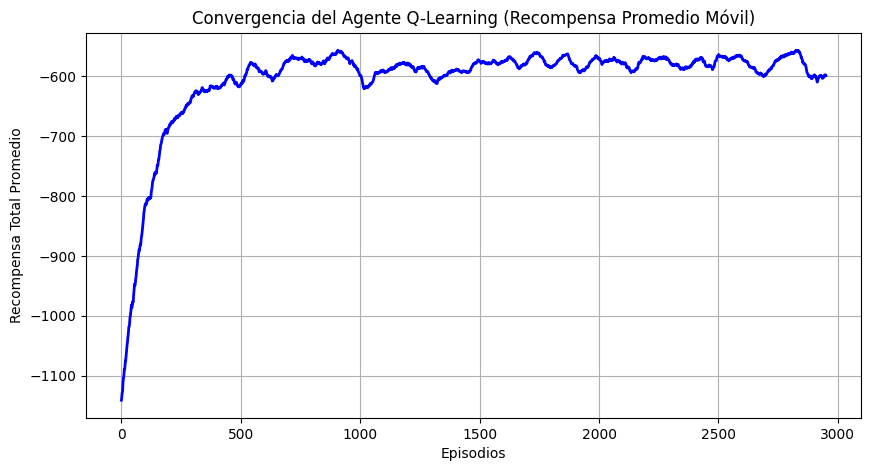

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random


### Problema a tratar: Optimización de inventarios ####
###Objetivo: El algoritmo debe minimizar los costos y maximizar las ganancias de acuerdo al stock existente y el que debería pedirse

#En primer lugar definimos las políticas o reglas de negocio

#En esta clase se definen los valores máximos por variable
class InventoryEnv:
    def __init__(self, max_inventory=10, max_order=6, holding_cost=1.0, order_cost=2.0, shortage_cost=5.0):
        self.max_inventory = max_inventory #El almacén debe tener una cantidad máxima de 10 unidades
        self.max_order = max_order #Es la cantidad máxima de productos que se pueden pedir al proveedor en un solo turno o día, en este caso se asignan 6
        self.holding_cost = holding_cost #Es el costo de almacenamiento. Representa cuanto cuesta mantener cada unidad guardada en el inventario por cada periodo de tiempo, en este caso 1.0 por día.
        self.order_cost = order_cost #Es el costo de pedir unidades nuevas. Representa el precio de adquirir o fabricar cada unidad nueva que se solicita al proveedor. En este caso 2.0
        self.shortage_cost = shortage_cost #Da a conocer cuando dinero se puerde por cada unidad que un cliente pide y no está disponible en el almacén, en este caso es 5.0.


        # Asignación de estados: Nivel de inventario de 0 a max_inventory ( es decir, en total habrán 11 estados). Los estados representan la cantidad de situaciones en las que puede encontrarse el almacén
        self.n_states = max_inventory + 1

        # Asignación de acciones: Cantidad a pedir de 0 a max_order (7 acciones). Son las acciones que puede hacer el agente, en este caso pedir entre 0 a 6 unidades por día
        self.n_actions = max_order + 1

        self.state = np.random.randint(0, max_inventory + 1) #Inicializa el inventario actual eligiendo un número entero al azar entre 0 y 10

     #Se crea este método para reiniciar el ambiente cada vez que se vaya a realizar una nueva simulación
    def reset(self):
        self.state = np.random.randint(0, self.max_inventory + 1) #permite generar un nuevo nivel de inventario inicial al azar (entre 0 y 10), sobrescribiendo el inventario en el que haya terminado la simulación anterior
        return self.state #Devuelve ese estado inicial que se acaba de calcular al agente para que sepa cuanta mercancía tiene disponible en el día 1 y pueda tomar su primera decisión de compra

     #Se crea este método para que se generen las acciones por día
    def step(self, action):
        # Costo fijo/variable de realizar el pedido. si se pide de una unidad en adelante se multiplica por el costo por la cantidad pedida; pero si no pide nada el costo es cero

        cost = self.order_cost * action if action > 0 else 0

        # Inventario disponible después de recibir el pedido (delimitado por la capacidad máxima que puede tener en el inventario). Se suma al inventario las unidades nuevas pedidas
        available_inventory = min(self.state + action, self.max_inventory)

        #Ahora se simulan cuantos productos quieren comprar los clientes ese día de forma aleatoria, pero siguiendo probabilidades definidas en la lista p. Ejemplo: Pedir 0 unidades será una probabilidad del 10% (0.1)
        demand = np.random.choice([0, 1, 2, 3, 4, 5], p=[0.1, 0.2, 0.4, 0.2, 0.05, 0.05])

        #Este bloque evalúa si la mercancía disponible en el almacén alcanzó para cubrir lo que pidieron los clientes ese día, calculando cuánto producto sobra o cuánto falta
        #Si el inventario es suficiente se restan los productos pedidos
        if available_inventory >= demand:
            ending_inventory = available_inventory - demand
            shortage = 0 #Indica que no habrá penalización porque todos los productos alcanzaron para los clientes
        #Si no es suficiente:
        else:
            ending_inventory = 0 #El inventario final queda en 0
            shortage = demand - available_inventory #Se calculan cuantas unidades faltaron para satisfacer las necesidades de todos los clientes. Este será el número de penalización

        # Ahora, de acuerdo a los resultados se genera un sistema de recompensas para que el agente sepa si es correcto el resultado o si es incorrecto
        holding_total = self.holding_cost * ending_inventory # Calcula el costo de almacenamiento del día multiplicando el costo unitario por las unidades que quedaron guardadas sin venderse
        shortage_total = self.shortage_cost * shortage # Calcula la penalización por no cumplir a los clientes multiplicando la multa unitaria por las unidades que los clientes pidieron y no se entregaron
        reward = -(cost + holding_total + shortage_total) # Suma los tres gastos del turno  y convierte el resultado a negativo. Es negativo porque al ser gastos la idea es que el agente busque el valor más cercano a cero. Si fueran ingresos si sería positivo


        # Actualiza el estado interno del almacén. Las unidades que sobraron al final del día se convierten en el inventario inicial disponible para el siguiente turno
        self.state = ending_inventory

        #Devolverá el inventario que quedó al día de hoy, la recompensa que se obtuvo en este turno y datos adicionales que pueden servir para cálculos si se necesitan
        return self.state, reward, False, {"demand": demand, "shortage": shortage}


# Se usa el algoritmo Q-Learning, creando la lógica del agente y también se definen las reglas de entrenamiento
env = InventoryEnv() #Se crea instancia con los valores máximos que se le asignaron en un principio
Q = np.zeros((env.n_states, env.n_actions))  #Se crea una matriz de aprendizaje 11x7 (EstadosxAcciones). Esta matriz funciona como la memoria del agente donde irá anotando qué tan rentable es tomar cada decisión en cada situación

# Hiperparámetros de aprendizaje-Estas variables a definir controlan como y cuanto aprende el algoritmo durante la simulación
alpha = 0.1       # Tasa de aprendizaje.Se define 0.1 para que aprenda de forma gradual y constante
gamma = 0.9       # Factor de descuento. Mide que tanto le importan al agente las ganancias o costos del futuro frente a los de hoy. Como 0.9 es cercano a 1, el agente es previsor y entiende que pedir hoy evita quedarse sin inventario mañana
epsilon = 1.0     # Tasa de exploración inicial-Se definen 100% de decisiones al azar para que valide todas las opciones posibles y no confíe de sus decisiones
epsilon_min = 0.01
epsilon_decay = 0.995 # Representa por cuanto se multiplicará cada episodio (epsilon) para ir reduciendo el azar hasta llegar a un mínimo de 0.01
n_episodes = 3000 #Se repetirá 3000 veces la simulación para que el agente practique lo suficiente

rewards_history = [] #Aqui se irá guardando el puntaje que vaya obteniendo por simulación

# Se inicia el Ciclo de Entrenamiento
for episode in range(n_episodes): #Repite el proceso 3000 veces
    state = env.reset() #Reinicia el almacén con un nivel de inventario aleatorio para empezar la simulación
    total_reward = 0 #Se pone en cero el contador de ganancias o recompensas

    for step in range(100): # 100 periodos por episodio
        # Toma de decisiones (Política Epsilon-Greedy)
        if random.uniform(0, 1) < epsilon: #Genera un número al azar entre 0 y 1. Si es menor que epsilon, el agente explora eligiendo una cantidad de pedido completamente aleatoria
            action = np.random.randint(0, env.n_actions)
        else:
        #Si no, el agente usa su conocimiento: Busca en la fila del inventario actual (estado) dentro de la Tabla Q y elige la acción que tenga el valor más alto (el menor costo esperado)
            action = np.argmax(Q[state, :])

        #Ejecución y aparendizaje
        next_state, reward, done, info = env.step(action) #Ejecuta el pedido en el almacén, recibe la demanda del día y obtiene el nuevo inventario  y la recompensa

        # Actualización de la Tabla Q (Ecuación de Bellman / Q-Learning)
        best_next_action = np.argmax(Q[next_state, :]) #Busca cuál sería la mejor decisión posible en el nuevo estado al que acaba de llegar
        td_target = reward + gamma * Q[next_state, best_next_action] #Calcula el valor real obtenido (el costo de hoy mas el mejor escenario posible descontado a futuro)
        td_error = td_target - Q[state, action] #Calcula la diferencia entre lo que realmente pasó y lo que el agente creía que iba a pasar
        Q[state, action] += alpha * td_error #Ajusta ligeramente el valor en la Tabla Q para que la próxima vez su predicción sea más exacta

        state = next_state #Avanza al dia siguiente
        total_reward += reward #Suma la recompensa del turno actual

    # Reducción de la exploración (epsilon decay)
    epsilon = max(epsilon_min, epsilon * epsilon_decay) # Al terminar los 100 días, reduce un poco el valor de epsilon (multiplicándolo por 0.995) para que en el siguiente episodio el agente tome menos decisiones al azar y confíe más en su Tabla Q, sin bajar nunca del 1%
    rewards_history.append(total_reward) #Guarda el resultado final de esos 100 días en el historial para poder evaluar su progreso


# Ahora se genera la Extracción de Resultados y Política Óptima

optimal_policy = np.argmax(Q, axis=1)  #Se busca en la tabla Q el puntaje mas alto

print("##Política óptima aprendida#")
print("Nivel de Inventario Actual ---> Cantidad Óptima a Pedir")
print("-" * 52) #Se agregan 52 guiones para separar los resultados y que se sepa más fácil que es lo que se está revisando
for inv_level, action in enumerate(optimal_policy): # Recorre la lista optimal_policy obteniendo al mismo tiempo el índice (inv_level, que va de 0 a 10) y la decisión óptima (action, que va de 0 a 6)
    print(f"Inventario: {inv_level:2d} unidades          ---> Pedir: {action} unidades") #Muestra las reglas finales

#Finalmente se realiza una gráfica para ver el desempeño
plt.figure(figsize=(10, 5))
# Suavizado de la recompensa acumulada por episodio
window = 50 #Calcula una media de cada 50 episodios.
smoothed_rewards = np.convolve(rewards_history, np.ones(window)/window, mode='valid') #esta operación matemática suaviza esos picos para que se vea claramente la tendencia real de mejora.
plt.plot(smoothed_rewards, color='b', linewidth=2) #Dibuja la línea
plt.title("Convergencia del Agente Q-Learning (Recompensa Promedio Móvil)") #Titulo
plt.xlabel("Episodios") #Nombre eje x
plt.ylabel("Recompensa Total Promedio") #Nombre eje y
plt.grid(True) #Se generan recuadros
plt.show() #Se muestra la gráfica